<h2 style="text-align:center">Keras</h2><br>

In [14]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import numpy as np
import scipy as sp
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from six.moves import range

In [15]:
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin']

dataset_car = pd.read_csv('auto-mpg.data', names=column_names,
                          na_values='?', comment='\t',
                          sep=' ', skipinitialspace=True)

In [16]:
dataset_car.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [17]:
dataset_car.isnull().sum()
dataset_car['Horsepower'].where(dataset_car['Horsepower'].notnull(), dataset_car['Horsepower'].mean(), inplace=True)
dataset_car.isnull().sum()


/tmp/ipykernel_629/1417853117.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset_car['Horsepower'].where(dataset_car['Horsepower'].notnull(), dataset_car['Horsepower'].mean(), inplace=True)


,0
MPG,0
Cylinders,0
Displacement,0
Horsepower,0
Weight,0
Acceleration,0
Model Year,0
Origin,0


In [18]:
dataset_car['Origin']
dataset_car = pd.get_dummies(dataset_car, columns=['Origin'])
dataset_car.columns

Index(['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight',
       'Acceleration', 'Model Year', 'Origin_1', 'Origin_2', 'Origin_3'],
      dtype='object')

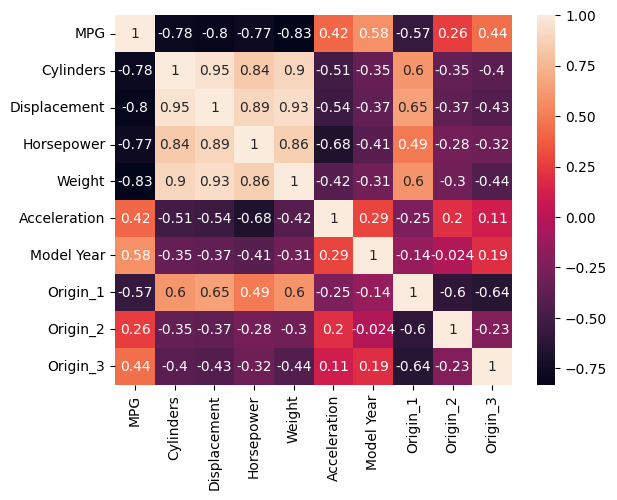

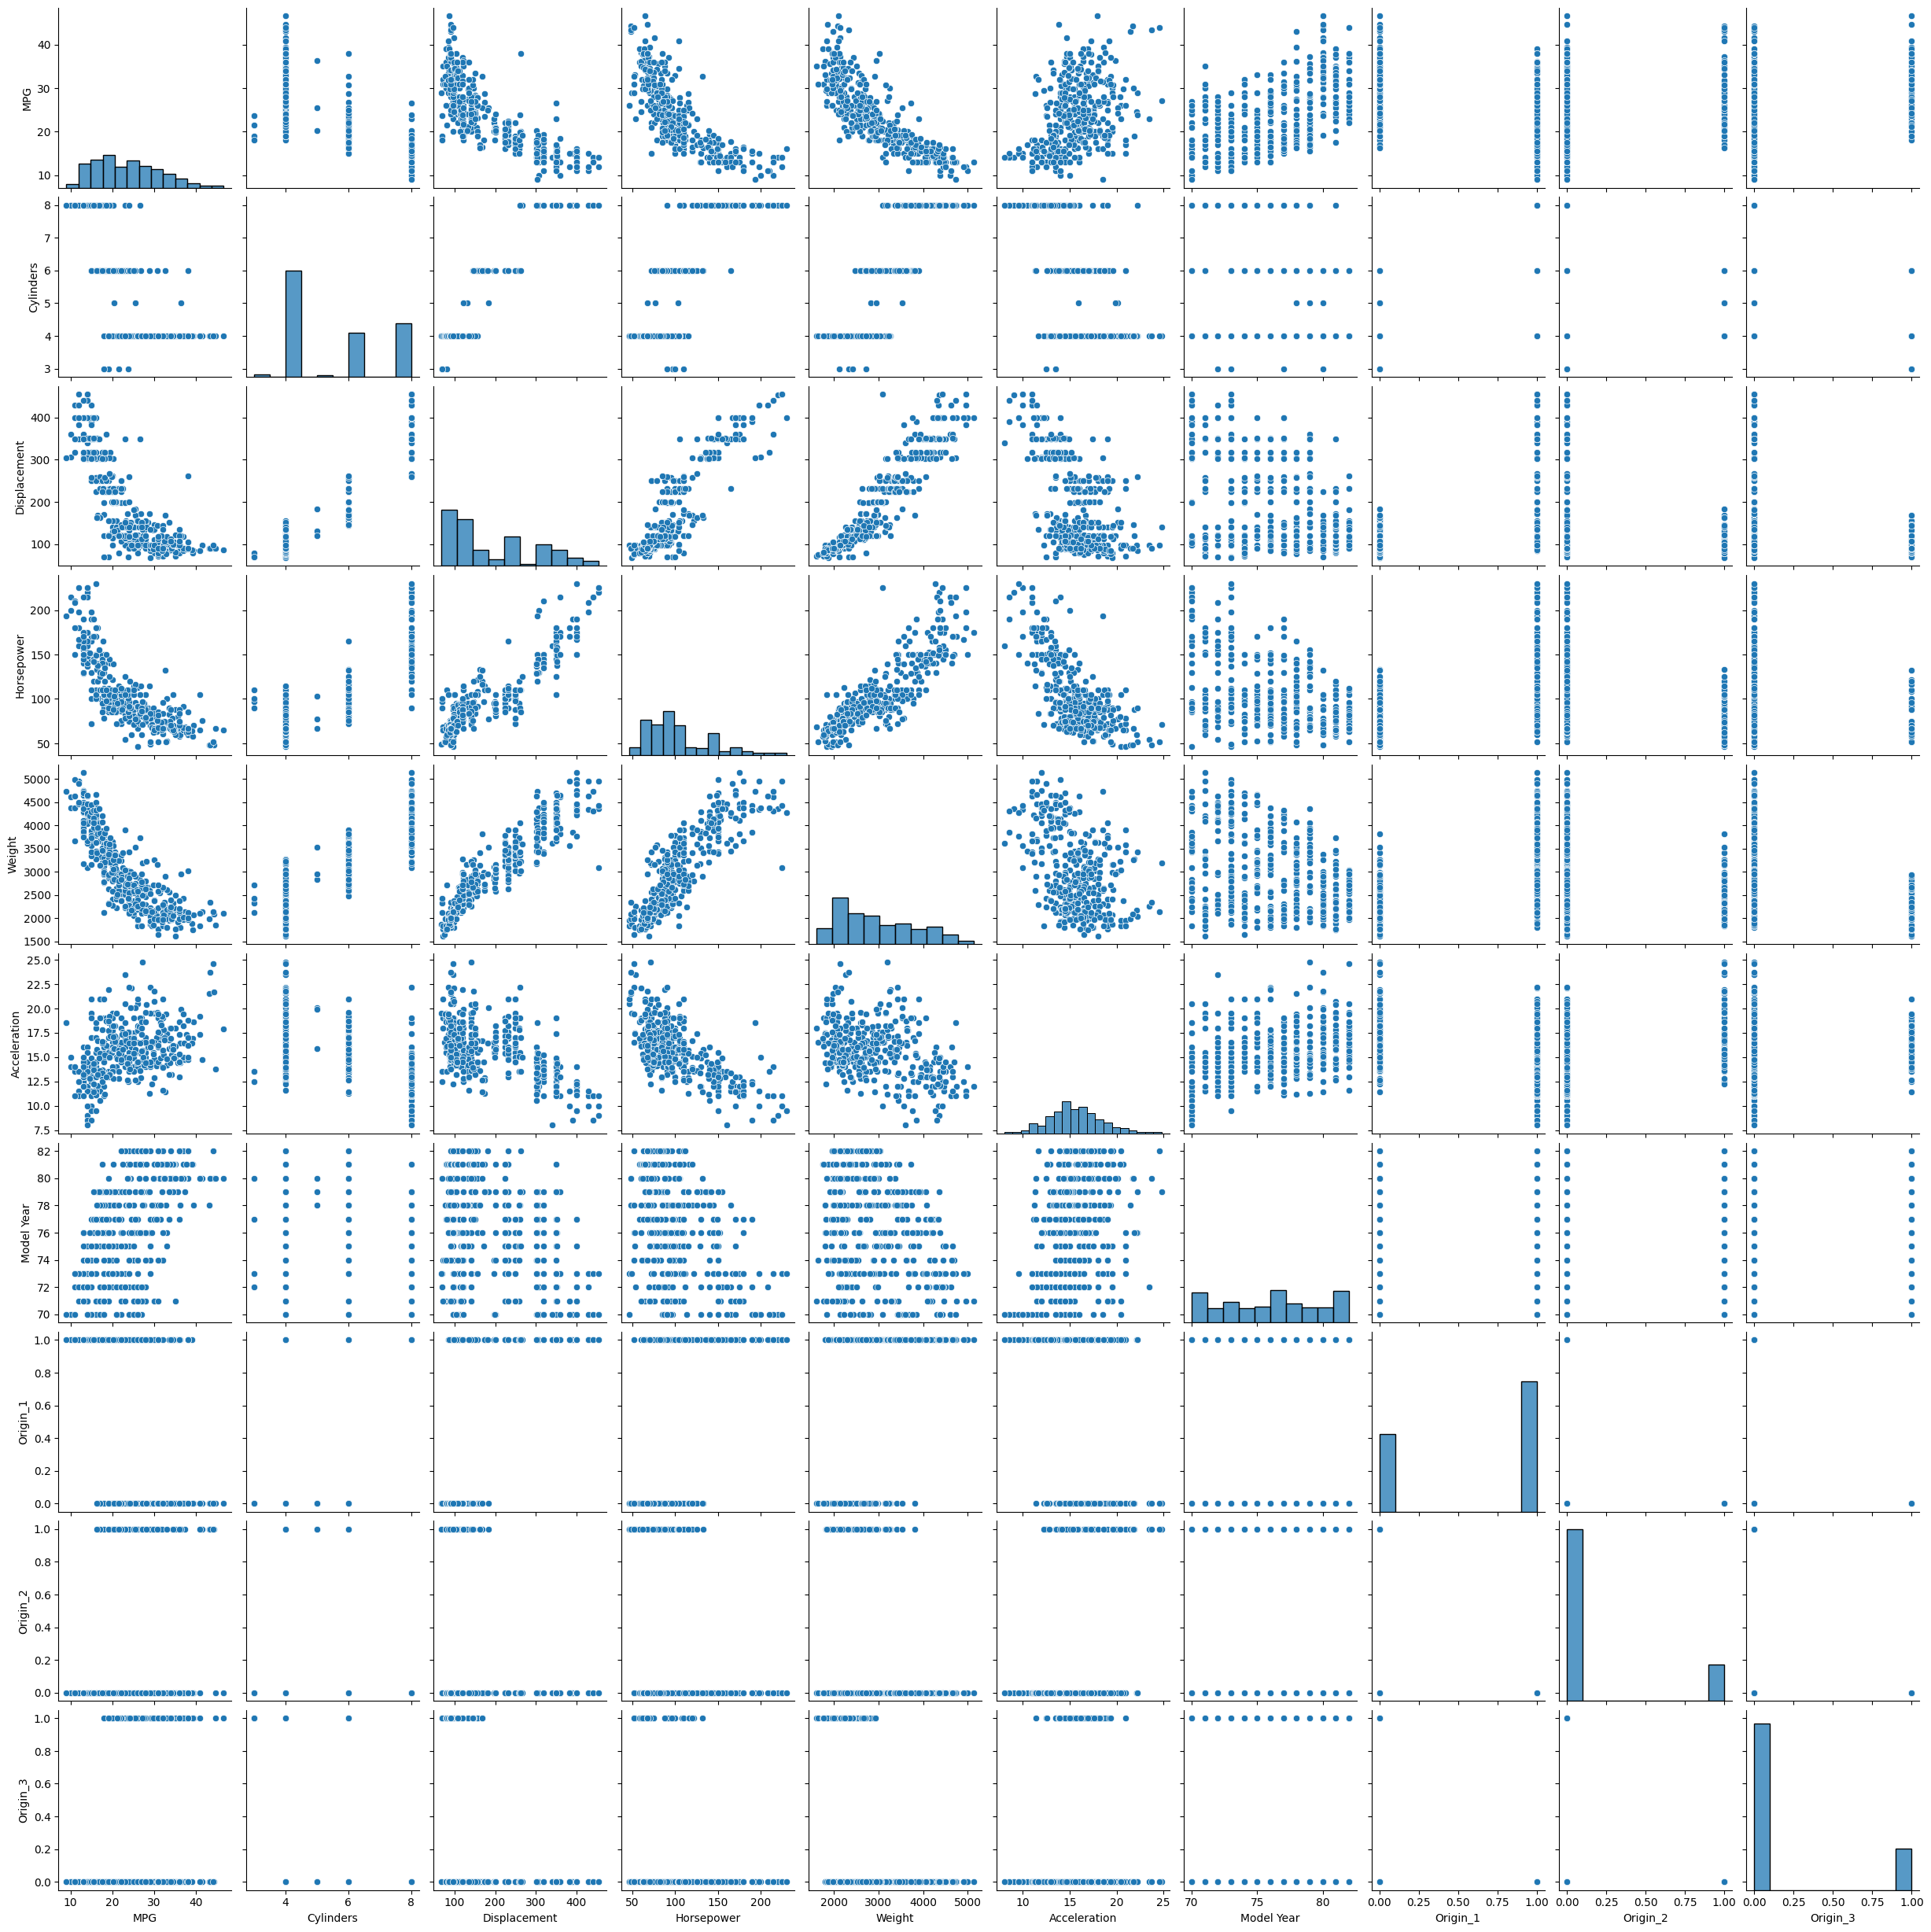

In [19]:
sns.heatmap(dataset_car.corr(), annot=True)
sns.pairplot(dataset_car)

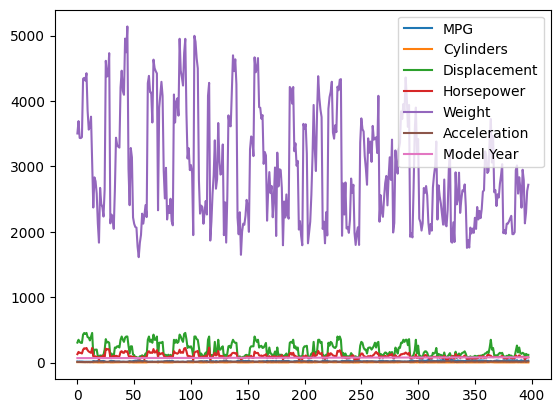

<Figure size 1000x600 with 0 Axes>

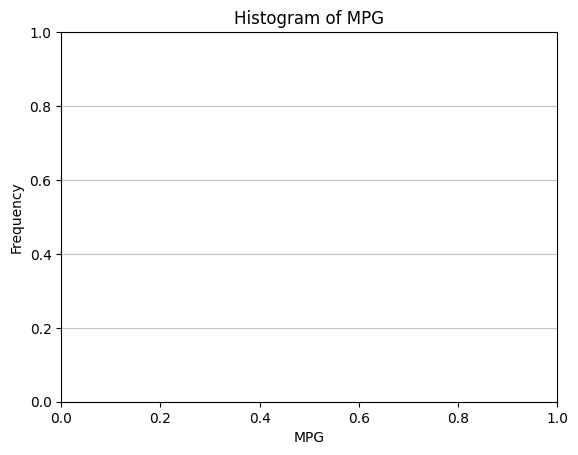

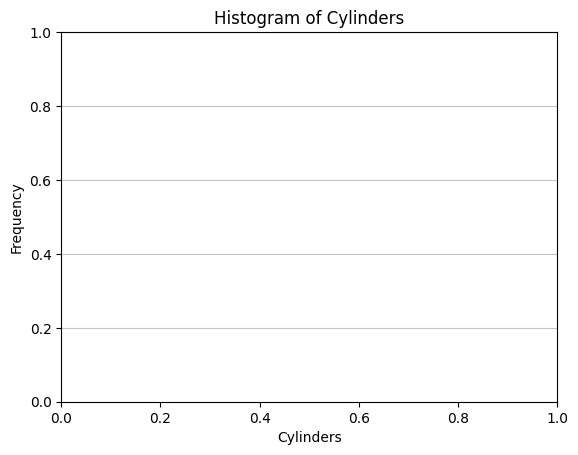

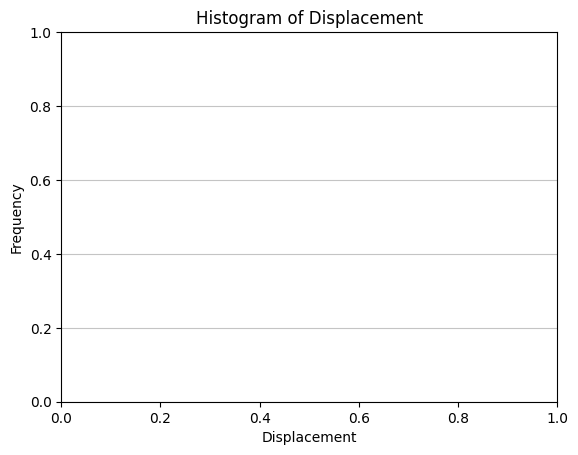

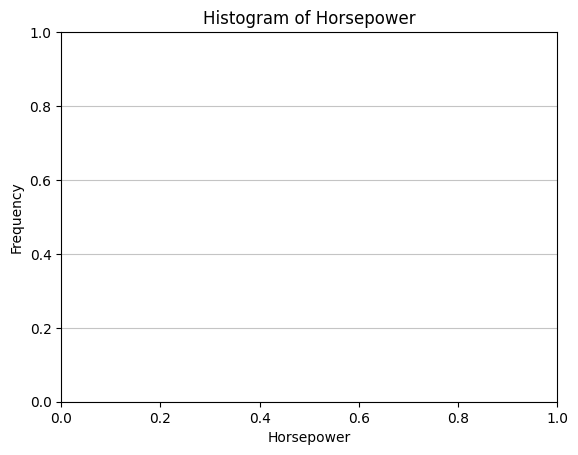

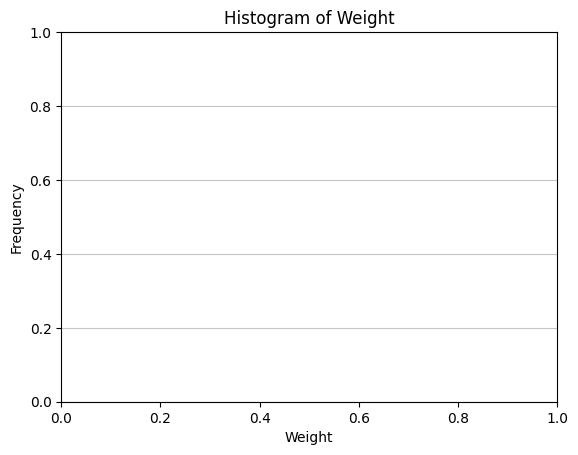

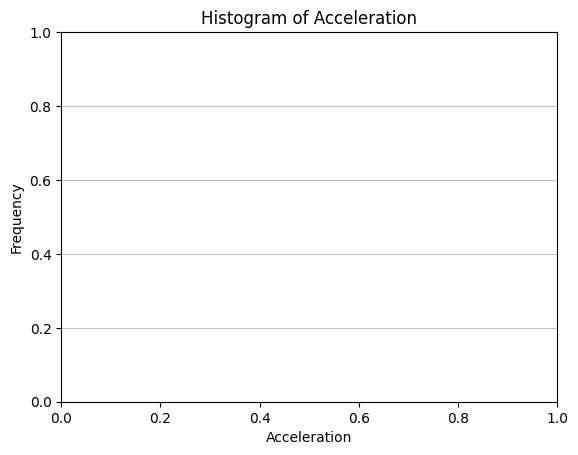

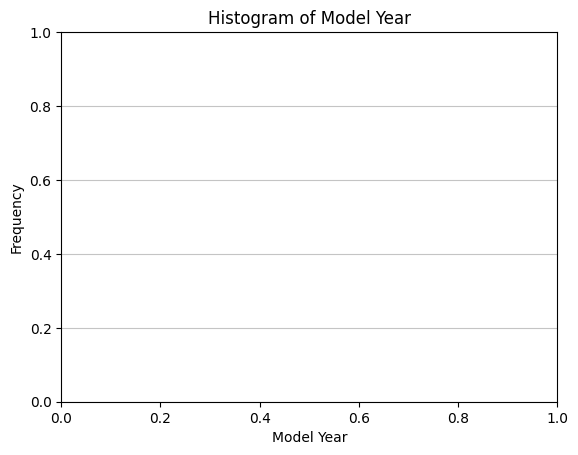

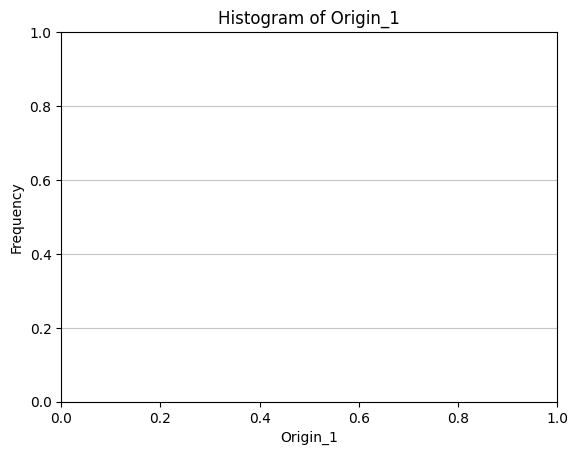

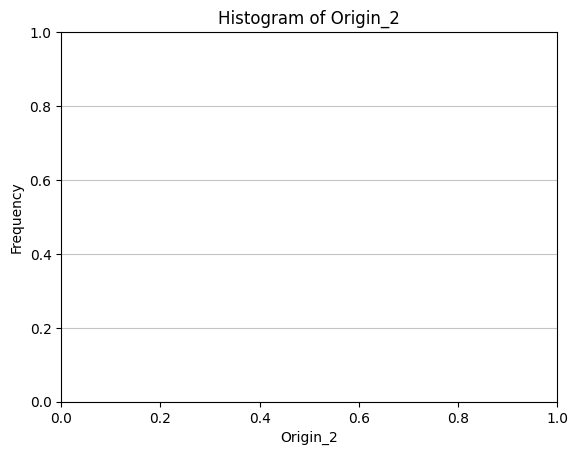

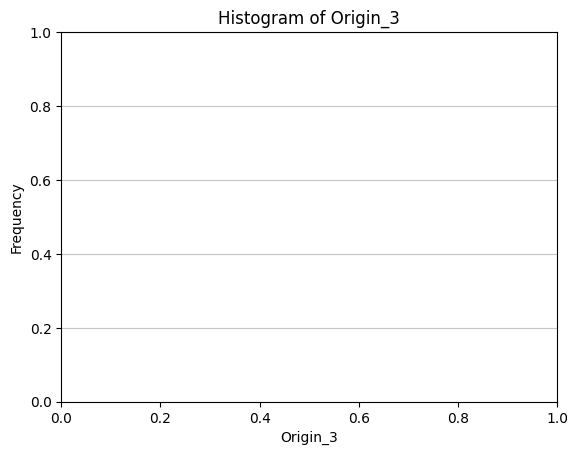

In [ ]:
lines = dataset_car.plot.line()
plt.figure(figsize=(10, 6))
plt.show()
for column in dataset_car.columns:
    plt.title(f'Histogram of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    #plt.hist(dataset_car[column], bins=10, color='blue')
    plt.grid(axis='y', alpha=0.75)
    plt.show()


In [21]:
X_car = dataset_car.drop("MPG", axis=1)
y_car = dataset_car["MPG"]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_car, X_test_car, y_train_car, y_test_car = train_test_split(X_car, y_car, test_size=0.23, random_state=56)

scaler = StandardScaler()
X_train_car_scaled = scaler.fit_transform(X_train_car)
X_test_car_scaled = scaler.transform(X_test_car)

X_train_car_scaled = pd.DataFrame(X_train_car_scaled, columns=X_train_car.columns)
X_test_car_scaled = pd.DataFrame(X_test_car_scaled, columns=X_test_car.columns)

In [48]:
!pip install tensorflow
import tensorflow as tf
from tensorflow import keras

model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=[X_train_car_scaled.shape[1]])
])
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3), loss=tf.keras.losses.MeanSquaredError(), metrics=[tf.keras.metrics.MeanAbsoluteError()])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            10 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10 (40.00 B)

 Trainable params: 10 (40.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# MSE is a classic regression loss finction for Regression problems.
# i will try a faster optimizer


In [49]:
linear_history = model.fit(X_train_car_scaled, y_train_car, epochs=3)

Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 603.4895 - mean_absolute_error: 23.4710  
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 575.6142 - mean_absolute_error: 23.0067 
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 549.6073 - mean_absolute_error: 22.5444 


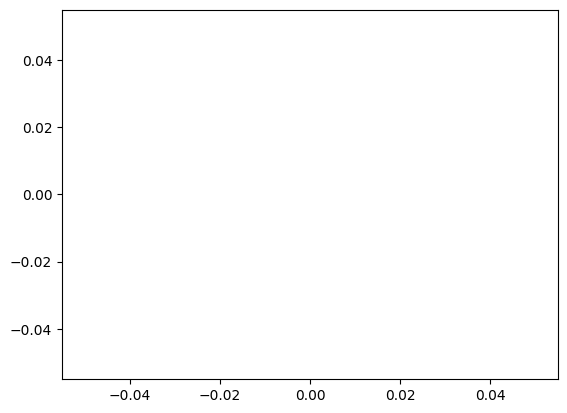

In [29]:
linear_history.history.keys()
plt.plot(linear_history.history['loss'], label='loss')
plt.show()

In [51]:
loss_linear_history = linear_history.history['loss']

In [ ]:
dnn_model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=[X_train_car_scaled.shape[1]]),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
# relu because it's a popular function often used in hidden layers.

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
dnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,865 (19.00 KB)

 Trainable params: 4,865 (19.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
dnn_model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.001), loss=tf.keras.losses.MeanSquaredError(), metrics=[tf.keras.metrics.MeanAbsoluteError()])
dnn_history = dnn_model.fit(X_train_car_scaled, y_train_car, epochs=3)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 551.4649 - mean_absolute_error: 22.1470  
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 265.3739 - mean_absolute_error: 14.4404 
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 37.8261 - mean_absolute_error: 4.8674 
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 18.1754 - mean_absolute_error: 3.2678 
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 14.0330 - mean_absolute_error: 2.9101 
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 12.0138 - mean_absolute_error: 2.6166
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 11.0411 - mean_absolute_error: 2.4753 
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 10.6563 - mean_absolute_error: 2.4198 
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 9.9238 - mean_absolute_error: 2.3289 
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 9.6072 - mean_absolute_error: 2.2407 
Epoch 11/100
10/1

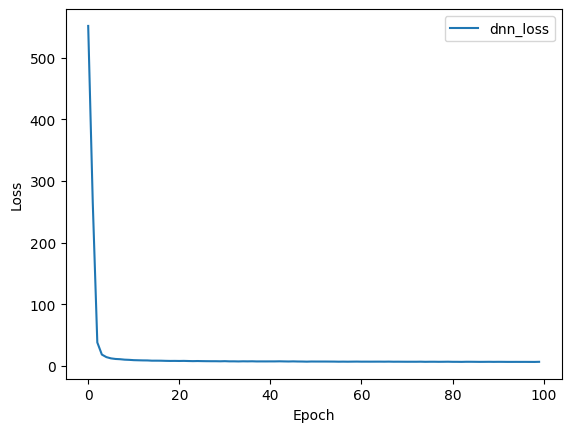

In [54]:
plt.plot(dnn_history.history['loss'], label='dnn_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [55]:
linear_predictions = model.predict(X_test_car_scaled).flatten()
dnn_predictions = dnn_model.predict(X_test_car_scaled).flatten()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


In [ ]:
linear_loss, linear_mae = model.evaluate(X_test_car_scaled, y_test_car, verbose=0)
dnn_loss, dnn_mae = dnn_model.evaluate(X_test_car_scaled, y_test_car, verbose=0)

print(f'Linear Model MAE: {linear_mae}')
print(f'DNN Model MAE: {dnn_mae}')

Linear Model Test MAE: 22.01
DNN Model Test MAE: 1.70


In [ ]:
# The RNN model is largly more accurate than the lienar model. This is thanks to activation function and the architecture of the RNN.

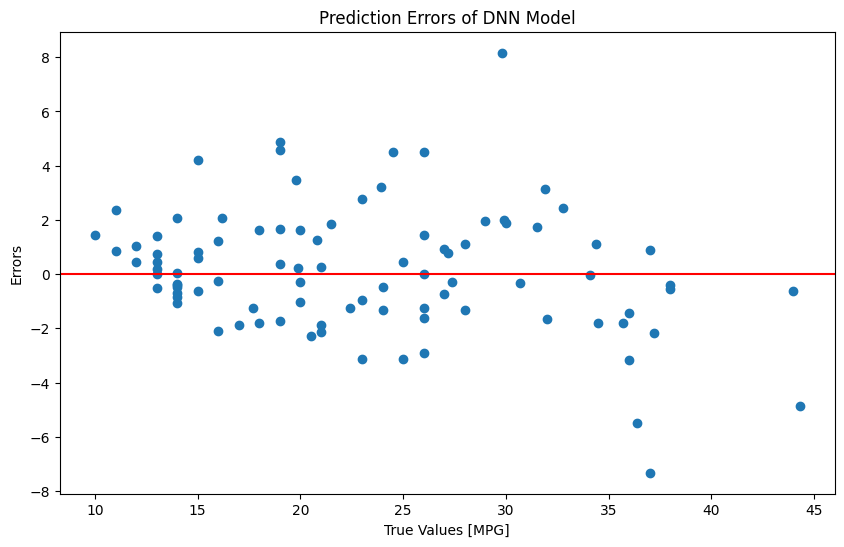

In [ ]:
errors = dnn_predictions - y_test_car
plt.figure(figsize=(10, 6))
plt.scatter(y_test_car, errors)
plt.xlabel('True MPG')
plt.ylabel('Error')
plt.axhline(y=0, color='r', linestyle='-')
plt.title('error RNN model')
plt.show()

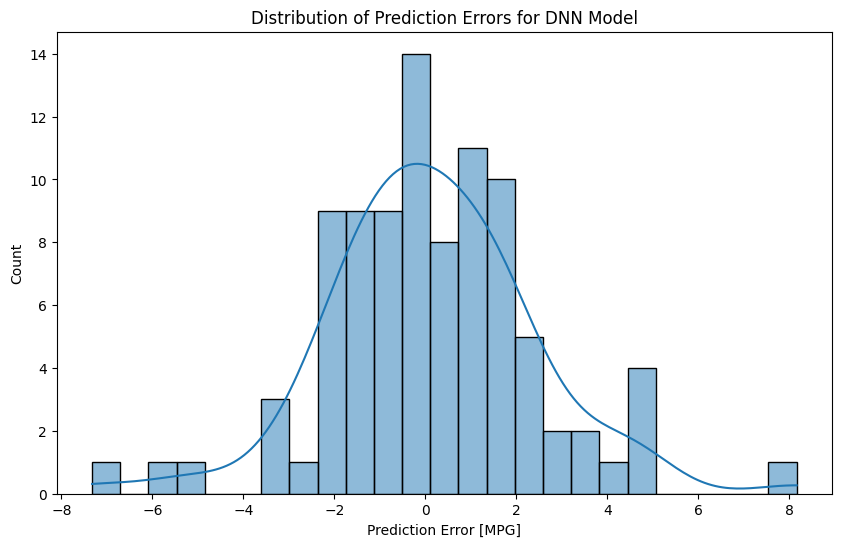

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(errors, bins=25, kde=True)
plt.xlabel('error MPG')
plt.title('error distribution')
plt.show()

In [ ]:
# Errors follows a normal distribution.